## Introducción al Torneado en la Manufactura Industrial

# Universidad Europea Madrid


El torneado es uno de los procesos de mecanizado más fundamentales en la industria manufacturera. Permite moldear piezas cilíndricas removiendo material mediante una herramienta de corte de un solo filo mientras la pieza gira a alta velocidad. Como ingenieros industriales, comprender la relación entre los parámetros de corte (velocidad, avance, profundidad) y las fuerzas resultantes es crucial para optimizar tiempos de producción, minimizar costos, diseñar procesos de fabricación eficientes y garantizar la vida útil de las máquinas y herramientas.

### 1. Cálculo del Tiempo de Maquinado y Fuerza de Corte

Vamos a utilizar un modelo simplificado para calcular los parámetros fundamentales de un proceso de cilindrado básico. Las ecuaciones clave que utilizaremos son:

1. **Velocidad de rotación del husillo ($N$, en RPM):**
$$N = \frac{V_c \cdot 1000}{\pi \cdot D_i}$$
Donde $V_c$ es la velocidad de corte en m/min y $D_i$ es el diámetro inicial de la pieza en mm.

2. **Área de la sección transversal de la viruta ($A_c$, en $\text{mm}^2$):**
$$A_c = f \cdot a_p$$
Donde $f$ es el avance en mm/rev y $a_p$ es la profundidad de pasada en mm.

3. **Fuerza de corte principal ($F_c$, en Newtons):**
$$F_c = A_c \cdot k_s = f \cdot a_p \cdot k_s$$
Donde $k_s$ es la presión específica de corte (fuerza específica) del material en MPa (o $\text{N/mm}^2$).

In [ ]:
import numpy as np # Importamos numpy para operaciones numéricas
import pandas as pd # Importamos pandas para organizar los datos
import matplotlib.pyplot as plt # Importamos pyplot para graficar los resultados

# Definimos los parámetros iniciales del proceso
diametro = 50.0 # Diámetro inicial de la pieza en milímetros (mm)
longitud = 150.0 # Longitud de corte de la pieza en milímetros (mm)
velocidad_corte = 120.0 # Velocidad de corte recomendada en metros por minuto (m/min)
avance = 0.2 # Avance de la herramienta en milímetros por revolución (mm/rev)
profundidad = 2.0 # Profundidad de pasada radial en milímetros (mm)
ks = 1500.0 # Presión específica de corte del material en Megapascales (MPa)

### 2. Cálculos Cinemáticos y de Fuerza

Calculamos las revoluciones por minuto (RPM), la fuerza de corte y la potencia requerida.

In [ ]:
# Calculamos la velocidad de rotación del husillo en RPM
rpm = (velocidad_corte * 1000) / (np.pi * diametro) # Fórmula estándar de RPM
# Calculamos la sección transversal de la viruta cortada en mm2
area_viruta = avance * profundidad # Área = avance x profundidad de pasada
# Calculamos la fuerza de corte estimada en Newtons (N)
fuerza_corte = area_viruta * ks # Fuerza = Área de viruta x Presión de corte
# Mostramos los resultados principales obtenidos
print(f"Velocidad del husillo: {rpm:.1f} RPM") # Imprime RPM con un decimal
print(f"Fuerza de corte estimada: {fuerza_corte:.1f} N") # Imprime la fuerza en Newtons

Velocidad del husillo: 763.9 RPM
Fuerza de corte estimada: 600.0 N


### 3. Visualización: Fuerza de Corte vs. Profundidad de Pasada

Analicemos gráficamente cómo incrementa la fuerza de corte a medida que aumentamos la profundidad de pasada (de 0.5 mm a 4.0 mm) manteniendo el avance constante.

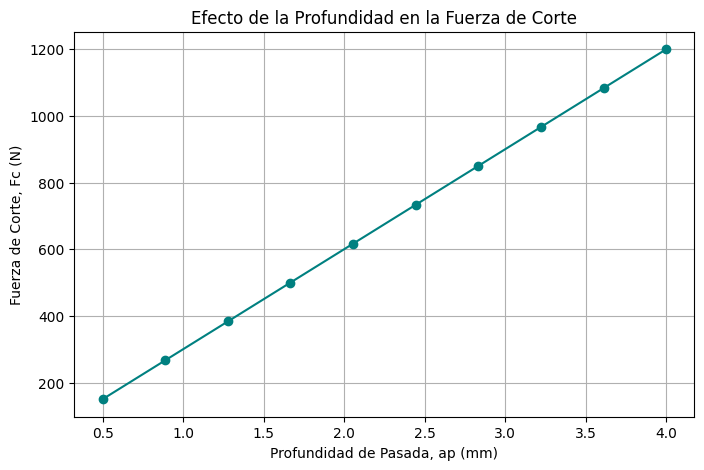

In [ ]:
# Creamos un rango de profundidades de pasada de 0.5 a 4.0 mm
profundidades = np.linspace(0.5, 4.0, 10) # 10 puntos intermedios generados
# Calculamos las fuerzas correspondientes para cada profundidad
fuerzas = avance * profundidades * ks # Calculo vectorial de la fuerza
# Iniciamos la construcción del gráfico
plt.figure(figsize=(8, 5)) # Definimos el tamaño del gráfico
plt.plot(profundidades, fuerzas, marker='o', color='teal') # Graficamos línea con marcadores
plt.title("Efecto de la Profundidad en la Fuerza de Corte") # Título del gráfico
plt.xlabel("Profundidad de Pasada, ap (mm)") # Etiqueta del eje X con unidades
plt.ylabel("Fuerza de Corte, Fc (N)") # Etiqueta del eje Y con unidades
plt.grid(True) # Añadimos cuadrícula de fondo
plt.show() # Desplegamos la figura en pantalla

### 3.1. Panel Interactivo de Parámetros de Corte

Utiliza los siguientes deslizadores (widgets) para modificar los parámetros iniciales en tiempo real y analizar cómo cambia la Fuerza de Corte de manera dinámica.

In [9]:
import ipywidgets as widgets
from ipywidgets import interact

def actualizar_torneado(d, vc, f, ap, ks_val):
    # Cálculos cinemáticos y de fuerza
    rpm_din = (vc * 1000) / (np.pi * d)
    area_din = f * ap
    fuerza_din = area_din * ks_val

    print("=" * 50)
    print(f"  Resultados con los parámetros seleccionados:")
    print("=" * 50)
    print(f"  -> Velocidad de rotación (N):        {rpm_din:.1f} RPM")
    print(f"  -> Área de viruta (Ac):              {area_din:.3f} mm²")
    print(f"  -> Fuerza de corte estimada (Fc):    {fuerza_din:.1f} N")
    print("=" * 50)

    # Graficar en vivo
    profundidades_rango = np.linspace(0.1, 5.0, 50)
    fuerzas_rango = f * profundidades_rango * ks_val

    plt.figure(figsize=(9, 4.5))
    plt.plot(profundidades_rango, fuerzas_rango, color='teal', label='Línea de tendencia (avance cte.)')
    plt.scatter([ap], [fuerza_din], color='red', s=100, zorder=5, label=f'Punto actual: {fuerza_din:.1f} N')
    plt.title("Fuerza de Corte vs. Profundidad de Pasada (Dinámico)")
    plt.xlabel("Profundidad de Pasada, ap (mm)")
    plt.ylabel("Fuerza de Corte, Fc (N)")
    plt.xlim(0, 5.2)
    plt.ylim(0, max(fuerzas_rango) * 1.1)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.show()

# Crear la interfaz interactiva
interact(
    actualizar_torneado,
    d=widgets.FloatSlider(value=50.0, min=10.0, max=150.0, step=5.0, description='Diámetro (mm)'),
    vc=widgets.FloatSlider(value=120.0, min=30.0, max=300.0, step=10.0, description='Vel. Corte (m/min)'),
    f=widgets.FloatSlider(value=0.2, min=0.05, max=1.0, step=0.05, description='Avance (mm/rev)'),
    ap=widgets.FloatSlider(value=2.0, min=0.1, max=5.0, step=0.1, description='Profundidad (mm)'),
    ks_val=widgets.FloatSlider(value=1500.0, min=500.0, max=3000.0, step=100.0, description='ks (MPa)')
);

interactive(children=(FloatSlider(value=50.0, description='Diámetro (mm)', max=150.0, min=10.0, step=5.0), Flo…

### 4. Predicción e Interacción

**Pregunta de Predicción 1:**
Si duplicamos el avance de la herramienta ($avance = 0.4$ mm/rev) pero reducimos la profundidad de pasada a la mitad ($profundidad = 1.0$ mm), ¿qué crees que ocurrirá con la fuerza de corte total?

*Haz tu predicción teórica, luego modifica los valores en la celda de abajo y ejecuta el código para comprobarlo.*

In [ ]:
# Modifica estos valores para comprobar tu predicción
nuevo_avance = 0.4 # Modifica este valor (original: 0.2)
nueva_profundidad = 1.0 # Modifica este valor (original: 2.0)
nueva_fuerza = nuevo_avance * nueva_profundidad * ks # Nueva fuerza de corte
print(f"Nueva Fuerza de Corte: {nueva_fuerza:.1f} N") # Imprime el nuevo resultado

Nueva Fuerza de Corte: 600.0 N


**Pregunta de Predicción 2:**
Si cambiamos el material de trabajo de acero a aluminio (cuya presión específica de corte $ks$ es menor, aproximadamente $700$ MPa), ¿la fuerza de corte aumentará o disminuirá?

*Predice el cambio, ajusta el valor de `ks_nuevo` abajo y ejecuta la celda.*

In [ ]:
# Ajusta el valor de ks para el aluminio u otro material
ks_nuevo = 700.0 # Cambia este parámetro para simular aluminio (original: 1500.0)
fuerza_aluminio = avance * profundidad * ks_nuevo # Fuerza calculada
print(f"Fuerza de corte con nuevo material: {fuerza_aluminio:.1f} N") # Muestra el resultado

Fuerza de corte con nuevo material: 280.0 N


### 5. Aplicación al Caso Real y Reflexión

**Pregunta Corta de Aplicación Real:**
Imagina que estás en la planta de producción de una empresa autopartista y el operario del torno te reporta que la herramienta se está rompiendo constantemente al maquinar ejes de transmisión de acero. Basándote en lo aprendido con la relación de variables físicas y fuerzas en este cuaderno, ¿qué decisiones operativas sugerirías implementar de inmediato en el taller para mitigar esta falla sin detener por completo la producción?

*Espacio para redactar tu respuesta en base a los datos analizados...*

**Pregunta de Reflexión Final:**
Como futuro Ingeniero/a Industrial encargado del diseño y planeación de procesos de manufactura, ¿por qué es crítico balancear la velocidad de producción (tiempos de ciclo cortos aumentando avances y profundidades) frente a las limitaciones físicas de la maquinaria y las herramientas de corte?